# Analisis de Backtesting Temporal — AutoML P2

Entregable visual minimo pedido por el enunciado: grafico de AUC por ola
(mes futuro) del modelo campeon, con una linea horizontal de referencia en
el `AUC_train`, para visualizar la degradacion (decay) del modelo a medida
que se aleja en el tiempo del periodo de entrenamiento.

Lee directamente `backtesting_results.json` y `results_summary.json` de la
ultima corrida guardada en `data/output/` — no vuelve a entrenar nada.

In [5]:
pip install matplotlib

     ---------------------------------------- 8.2/8.2 MB 27.6 MB/s eta 0:00:00
     ------------------------------------- 221.2/221.2 KB 14.1 MB/s eta 0:00:00
     ---------------------------------------- 1.6/1.6 MB 50.7 MB/s eta 0:00:00
     ---------------------------------------- 7.2/7.2 MB 38.4 MB/s eta 0:00:00
     ---------------------------------------- 70.6/70.6 KB 3.8 MB/s eta 0:00:00
     ---------------------------------------- 126.4/126.4 KB ? eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
You should consider upgrading via the 'c:\Users\meycr\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [6]:
import json
import os
import glob

import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = '../data/output'  # ejecutar desde notebooks/; ajustar si es necesario

carpetas = sorted(glob.glob(os.path.join(OUTPUT_DIR, '*')))
carpeta_corrida = carpetas[-1]  # la corrida mas reciente
print('Leyendo corrida:', carpeta_corrida)

with open(os.path.join(carpeta_corrida, 'backtesting_results.json'), encoding='utf-8') as f:
    backtesting = json.load(f)

with open(os.path.join(carpeta_corrida, 'results_summary.json'), encoding='utf-8') as f:
    resumen = json.load(f)

campeon_nombre = resumen['campeon_final_tras_backtesting']['ml_name']
auc_train = resumen['campeon_final_tras_backtesting']['performance']['auc_train']
print('Modelo campeon:', campeon_nombre, '| AUC train:', auc_train)


Leyendo corrida: ../data/output\2026-10-07_02-17-02
Modelo campeon: XGBoost_hpo | AUC train: 0.8663


## Tabla de olas (walk-forward)

In [7]:
tabla_olas = pd.DataFrame(backtesting['waves'])
tabla_olas


,partition,p_fecinformacion,auc,decay_pct,n_obs,psi,psi_interpretacion
0,p3,20220501,0.8502,1.86,322356,0.0051,sin cambio significativo
1,p4,20220601,0.8558,1.21,304813,0.0058,sin cambio significativo
2,p5,20220701,0.8605,0.67,295732,0.0092,sin cambio significativo
3,p6,20220801,0.8385,3.21,236914,0.0426,sin cambio significativo
4,p7,20220901,0.8325,3.90,244666,0.0248,sin cambio significativo
5,p8,20221001,0.8453,2.42,240726,0.0206,sin cambio significativo
6,p9,20221101,0.8500,1.88,263753,0.0185,sin cambio significativo
7,p10,20221201,0.8578,0.98,317378,0.0042,sin cambio significativo


## Grafico: AUC por ola vs. AUC de entrenamiento

La linea punteada horizontal es el `AUC_train` (el techo "sano" del modelo).
Cada punto es una particion/mes futuro que NUNCA participo en el
entrenamiento. Mientras mas se alejan los puntos de la linea hacia abajo,
mayor es el decay temporal (ver columna `decay_pct`).

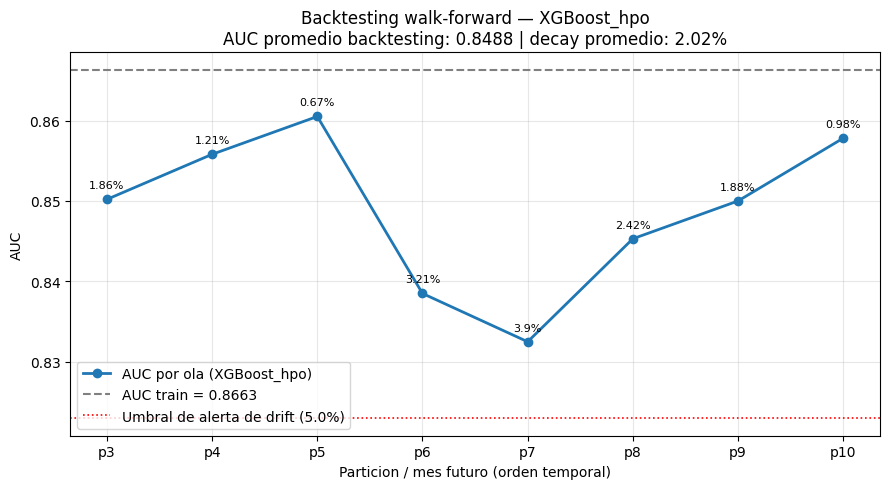

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(tabla_olas['partition'], tabla_olas['auc'], marker='o', linewidth=2,
        color='#1f77b4', label=f'AUC por ola ({campeon_nombre})')
ax.axhline(y=auc_train, color='gray', linestyle='--', linewidth=1.5,
           label=f'AUC train = {auc_train}')

umbral = backtesting['drift_alert_threshold']
ax.axhline(y=auc_train * (1 - umbral / 100), color='red', linestyle=':',
           linewidth=1.2, label=f'Umbral de alerta de drift ({umbral}%)')

for _, fila in tabla_olas.iterrows():
    ax.annotate(f"{fila['decay_pct']}%", (fila['partition'], fila['auc']),
                textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)

ax.set_xlabel('Particion / mes futuro (orden temporal)')
ax.set_ylabel('AUC')
ax.set_title(f'Backtesting walk-forward — {campeon_nombre}\n'
             f"AUC promedio backtesting: {backtesting['avg_auc_backtest']} "
             f"| decay promedio: {backtesting['avg_decay_backtest']}%")
ax.legend(loc='lower left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(carpeta_corrida, 'backtesting_auc_por_ola.png'), dpi=150)
plt.show()


## Grafico: PSI por ola (concept drift)

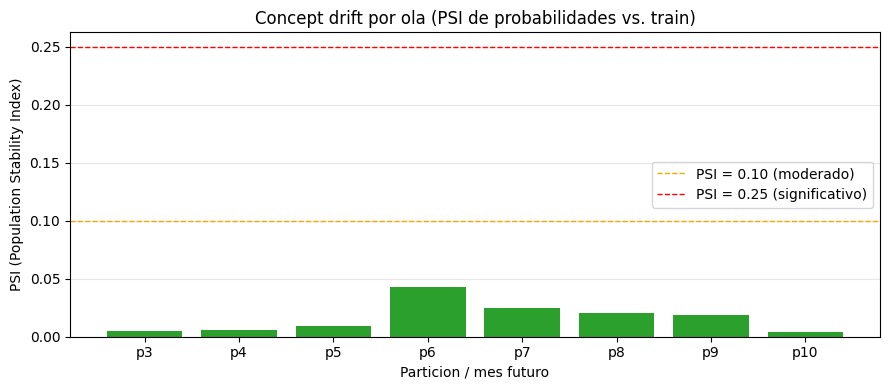

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
colores = ['#2ca02c' if p < 0.10 else '#ff7f0e' if p < 0.25 else '#d62728'
           for p in tabla_olas['psi']]
ax.bar(tabla_olas['partition'], tabla_olas['psi'], color=colores)
ax.axhline(y=0.10, color='orange', linestyle='--', linewidth=1, label='PSI = 0.10 (moderado)')
ax.axhline(y=0.25, color='red', linestyle='--', linewidth=1, label='PSI = 0.25 (significativo)')
ax.set_xlabel('Particion / mes futuro')
ax.set_ylabel('PSI (Population Stability Index)')
ax.set_title('Concept drift por ola (PSI de probabilidades vs. train)')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(os.path.join(carpeta_corrida, 'backtesting_psi_por_ola.png'), dpi=150)
plt.show()


## Conclusion automatica

In [10]:
if backtesting['drift_severo_en_todas_las_olas']:
    print('ALERTA SEVERA: el modelo supero el umbral de decay en TODAS las olas futuras.')
    print('El sistema habria intentado cambiar de campeon (ver motivo_cambio_backtesting en results_summary.json).')
elif backtesting['drift_alert']:
    print('Alerta parcial: al menos una ola supero el umbral de decay, pero no todas.')
    print('El campeon se mantiene (estabilidad aceptable en el resto de olas).')
else:
    print('Sin alertas de drift: el campeon se mantiene estable en todas las olas evaluadas.')

print(f"Motivo de cambio de campeon: {resumen.get('motivo_cambio_backtesting')}")


Sin alertas de drift: el campeon se mantiene estable en todas las olas evaluadas.
Motivo de cambio de campeon: None
